# 01 - Tabular EDA, merge validation and the product model

**Member 1** | Formative 2: authentication and product recommendation.

This notebook covers every task in README section 9. It explores the two raw
tabular files, proves that a naive join inflates the data, builds one validated
analysis-ready dataset, and trains the product-category model handed to Member 4.

The reusable logic does **not** live in this notebook (README task 18): it is in
`src/preprocess_tabular.py` and `src/train_product_model.py`, and the cells below
call those functions. Run the notebook top to bottom; the setup cell locates the
repository root itself, so it works whether Jupyter starts in the repository root
or in `notebooks/`.

| Section | README task |
| --- | --- |
| 1. Load the raw files | 1-2 |
| 2. Data-quality audit | 3 |
| 3. EDA plots 1-2 | 4 |
| 4. Normalise the join key | 5 |
| 5. Validate the relationship | 6 |
| 6. Aggregation strategy | 7 |
| 7. Merge and row counts | 8 |
| 8. EDA plots 3-6 on the merged data | 4 |
| 9. History features without leakage | 9-10 |
| 10. Save `merged_dataset.csv` | 11 |
| 11. Model features and preprocessing | 12-13 |
| 12. Grouped split, baselines and metrics | 14-16 |
| 13. Save the pipeline and predict | 17-18 |

Plot 1-2 use only the raw tables; plot 3-6 need the merged table, so they follow
the merge. Every plot is labelled and followed by its written interpretation.

In [1]:
%matplotlib inline

import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)


def find_repo_root(start: Path) -> Path:
    """Walk upwards from the working directory until data/raw is found."""
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "raw" / "customer_transactions.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Open this notebook from inside a clone of Formative-2-machine-learning "
        "(the folder that contains data/raw/)."
    )


REPO_ROOT = find_repo_root(Path.cwd().resolve())
sys.path.insert(0, str(REPO_ROOT / "src"))

import preprocess_tabular as pt
import train_product_model as tpm

FIGURES = REPO_ROOT / "outputs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)


def save_and_show(figure, filename: str) -> None:
    """Save a figure into outputs/figures and display it inline."""
    figure.tight_layout()
    figure.savefig(FIGURES / filename, dpi=150, bbox_inches="tight")
    plt.show()


print("Repository root:", REPO_ROOT)
print("pandas", pd.__version__)

Repository root: D:\class repo\formative2
pandas 3.0.3


## 1. Load the raw files  (tasks 1-2)

Both CSVs are read exactly as provided. `purchase_date` is parsed as a date for
plotting and for ordering a customer's purchases; the files on disk are untouched.

In [2]:
social_raw, transactions_raw = pt.load_raw()

print(f"customer_social_profiles.csv -> {social_raw.shape[0]} rows x {social_raw.shape[1]} columns")
print(f"customer_transactions.csv    -> {transactions_raw.shape[0]} rows x {transactions_raw.shape[1]} columns")

customer_social_profiles.csv -> 155 rows x 5 columns
customer_transactions.csv    -> 150 rows x 6 columns


In [3]:
print("=== customer_social_profiles.csv ===")
display(social_raw.head())
display(pd.DataFrame({
    "dtype": social_raw.dtypes.astype(str),
    "non_null": social_raw.notna().sum(),
    "unique": social_raw.nunique(),
}))

print("=== customer_transactions.csv ===")
display(transactions_raw.head())
display(pd.DataFrame({
    "dtype": transactions_raw.dtypes.astype(str),
    "non_null": transactions_raw.notna().sum(),
    "unique": transactions_raw.nunique(),
}))

=== customer_social_profiles.csv ===


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


,dtype,non_null,unique
customer_id_new,str,155,84
social_media_platform,str,155,5
engagement_score,int64,155,50
purchase_interest_score,float64,155,40
review_sentiment,str,155,3


=== customer_transactions.csv ===


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


,dtype,non_null,unique
customer_id_legacy,int64,150,75
transaction_id,int64,150,150
purchase_amount,int64,150,120
purchase_date,datetime64[us],150,150
product_category,str,150,5
customer_rating,float64,140,37


In [4]:
print("=== summary statistics: social profiles ===")
display(social_raw.describe().T)
print("=== summary statistics: transactions ===")
display(transactions_raw.describe().T)

=== summary statistics: social profiles ===


,count,mean,std,min,25%,50%,75%,max
engagement_score,155.0,75.606452,14.568021,50.0,63.50,77.0,87.5,99.0
purchase_interest_score,155.0,3.152903,1.142867,1.0,2.35,3.2,4.1,5.0


=== summary statistics: transactions ===


,count,mean,min,25%,50%,75%,max,std
customer_id_legacy,150.0,148.76,100.0,121.25,150.5,174.75,199.0,30.046425
transaction_id,150.0,1075.5,1001.0,1038.25,1075.5,1112.75,1150.0,43.445368
purchase_amount,150.0,280.78,51.0,179.0,274.0,388.5,495.0,121.329595
purchase_date,150,2024-03-15 12:00:00,2024-01-01 00:00:00,2024-02-07 06:00:00,2024-03-15 12:00:00,2024-04-21 18:00:00,2024-05-29 00:00:00,NaN
customer_rating,140.0,2.985,1.0,1.95,3.0,4.0,5.0,1.20699


**Interpretation.** The social file holds 155 rows over 5 columns: a customer
identifier, a platform, a 50-99 `engagement_score`, a 1-5
`purchase_interest_score` and a three-level `review_sentiment`. The transaction
file holds 150 rows: a legacy numeric identifier, a transaction identifier, a
51-495 `purchase_amount`, a date spanning 2024-01-01 to 2024-05-29, a
`product_category` and a 1-5 `customer_rating`. The `unique` column is the first
warning sign: neither file has 155 or 150 distinct customers, so both are
customer-repeated tables, not one-row-per-customer tables.

## 2. Data-quality audit  (task 3)

Missing values, exact duplicates and repeated identifiers, computed by
`pt.audit_raw`.

In [5]:
audit = pt.audit_raw(social_raw, transactions_raw)

quality = pd.DataFrame(
    {
        "social_profiles": [
            audit["social_rows"],
            audit["social_unique_customers"],
            audit["social_duplicate_identifier_rows"],
            audit["social_exact_duplicate_rows"],
            sum(audit["social_missing_values"].values()),
            audit["social_rows_per_customer_max"],
        ],
        "transactions": [
            audit["transaction_rows"],
            audit["transaction_unique_customers"],
            audit["transaction_duplicate_identifier_rows"],
            audit["transaction_exact_duplicate_rows"],
            sum(audit["transaction_missing_values"].values()),
            audit["transaction_rows_per_customer_max"],
        ],
    },
    index=[
        "rows",
        "unique customer ids",
        "rows repeating an existing customer id",
        "exact duplicate rows",
        "missing values in total",
        "max rows for a single customer",
    ],
)
display(quality)

print("Missing values per column:")
display(pd.DataFrame({
    "social_profiles": pd.Series(audit["social_missing_values"]),
    "transactions": pd.Series(audit["transaction_missing_values"]),
}).fillna(0).astype(int))

,social_profiles,transactions
rows,155,150
unique customer ids,84,75
rows repeating an existing customer id,71,0
exact duplicate rows,5,0
missing values in total,0,10
max rows for a single customer,7,6


Missing values per column:


,social_profiles,transactions
customer_id_legacy,0,0
customer_id_new,0,0
customer_rating,0,10
engagement_score,0,0
product_category,0,0
purchase_amount,0,0
purchase_date,0,0
purchase_interest_score,0,0
review_sentiment,0,0
social_media_platform,0,0


In [6]:
print("Transactions whose customer has no social profile:",
      len(audit["transaction_ids_without_social"]))
print(audit["transaction_ids_without_social"])

print("\nSocial customers who never transacted:",
      len(audit["social_ids_without_transactions"]))
print(audit["social_ids_without_transactions"])

print("\nCustomers present in both files:", audit["shared_customers"])

Transactions whose customer has no social profile: 14
[108, 110, 123, 134, 136, 153, 157, 159, 161, 164, 170, 171, 175, 184]

Social customers who never transacted: 23
[109, 112, 115, 116, 118, 124, 126, 131, 142, 145, 155, 156, 165, 166, 167, 168, 169, 176, 178, 193, 195, 196, 197]

Customers present in both files: 61


**Interpretation.** Three defects matter.

1. **Repeated identifiers, not duplicate rows.** 71 social rows repeat an
   existing customer id (155 rows, 84 customers), and the 150 transaction rows
   belong to only 75 customers - though no `transaction_id` value is duplicated.
   A customer appears up to 7 times in the social file and up to 6 times in the
   transaction file.
2. **Five exact duplicate social rows.** They are genuine copies, so keeping
   them would over-weight those customers when averaging. The aggregation step
   absorbs them by averaging, and the count stays visible here for the record.
3. **Missing values.** Only `customer_rating` is incomplete: 10 of 150 ratings are
   absent. The social file is complete. Nothing else needs imputation at the raw
   stage.

The overlap is 61 customers. That single number sets the ceiling on the whole
study: 14 transacting customers have no social profile (33 of 150 transactions),
and 23 social customers never bought anything, so their profile can never be
paired with a label.

## 3. EDA plots 1-2  (task 4)

The first two plots only need the raw tables.

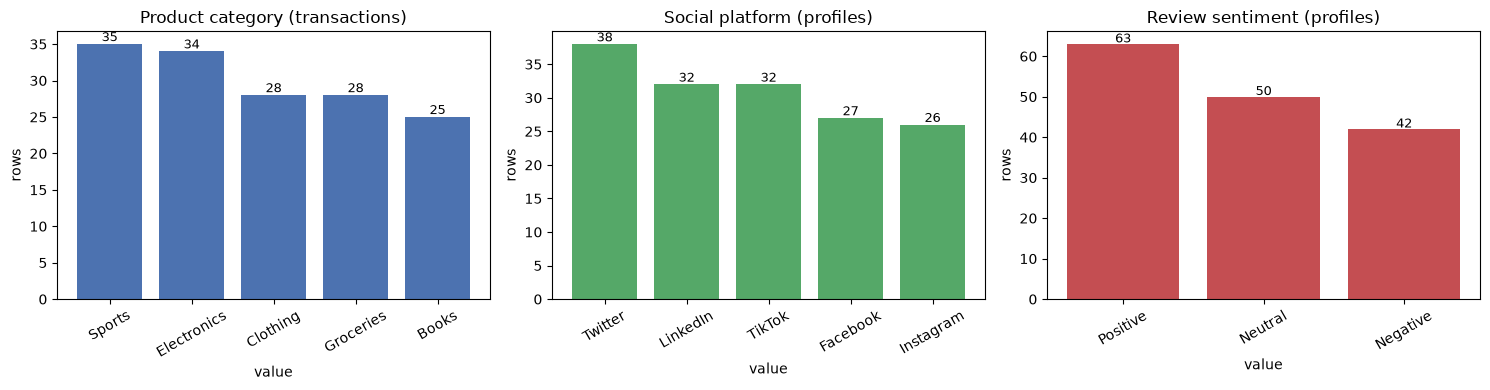

majority-class share of transactions: 0.233


In [7]:
category_counts = transactions_raw["product_category"].value_counts()
platform_counts = social_raw["social_media_platform"].value_counts()
sentiment_counts = social_raw["review_sentiment"].value_counts()

figure, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, counts, title, colour in zip(
    axes,
    [category_counts, platform_counts, sentiment_counts],
    ["Product category (transactions)", "Social platform (profiles)", "Review sentiment (profiles)"],
    ["#4C72B0", "#55A868", "#C44E52"],
):
    axis.bar(counts.index.astype(str), counts.values, color=colour)
    axis.set_title(title)
    axis.set_xlabel("value")
    axis.set_ylabel("rows")
    axis.tick_params(axis="x", rotation=30)
    for position, value in enumerate(counts.values):
        axis.text(position, value + 0.4, str(value), ha="center", fontsize=9)

save_and_show(figure, "01_category_platform_sentiment_balance.png")

print("majority-class share of transactions:",
      f"{category_counts.iloc[0] / len(transactions_raw):.3f}")

**Interpretation (plot 1).** The target is close to balanced: Sports 35,
Electronics 34, Clothing 28, Groceries 28, Books 25. No class is rare enough to
need resampling, but the imbalance also means a model that always predicts
Sports already scores **0.233 accuracy** without learning anything. That is the
number to beat, not zero. The platforms are balanced as well (Instagram 26 to
Twitter 38), so no platform dominates the social features. Sentiment leans
positive (63 Positive, 50 Neutral, 42 Negative), which is mild enough to keep.

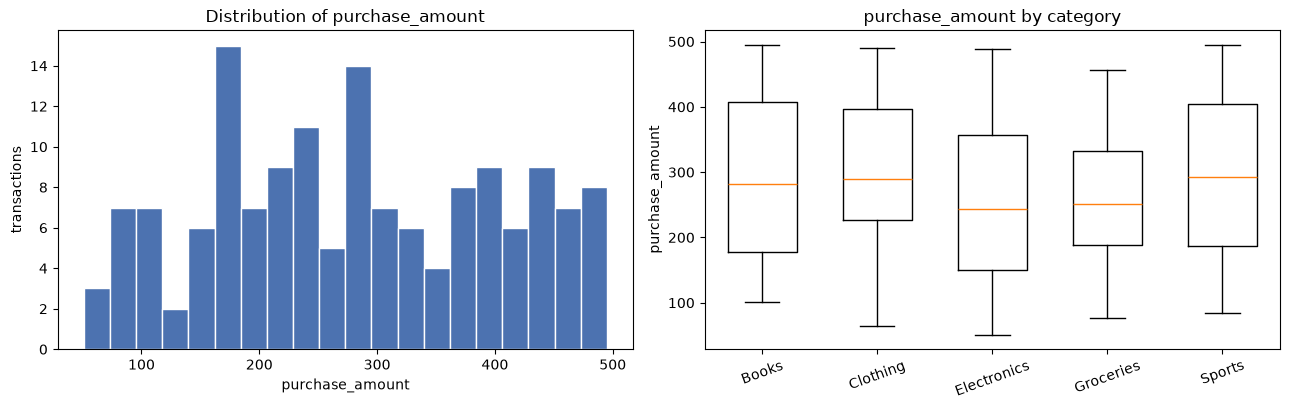

Q1=179.0  Q3=388.5  IQR=209.5  fences=(-135.2, 702.8)
rows outside the fences: 0


In [8]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].hist(transactions_raw["purchase_amount"], bins=20, color="#4C72B0", edgecolor="white")
axes[0].set_title("Distribution of purchase_amount")
axes[0].set_xlabel("purchase_amount")
axes[0].set_ylabel("transactions")

categories = sorted(transactions_raw["product_category"].unique())
positions = list(range(1, len(categories) + 1))
axes[1].boxplot(
    [transactions_raw.loc[transactions_raw["product_category"] == c, "purchase_amount"] for c in categories],
    positions=positions,
    widths=0.6,
)
axes[1].set_xticks(positions, categories, rotation=20)
axes[1].set_title("purchase_amount by category")
axes[1].set_ylabel("purchase_amount")

save_and_show(figure, "02_purchase_amount_distribution.png")

q1, q3 = transactions_raw["purchase_amount"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outside = transactions_raw[
    (transactions_raw["purchase_amount"] < lower) | (transactions_raw["purchase_amount"] > upper)
]
print(f"Q1={q1:.1f}  Q3={q3:.1f}  IQR={iqr:.1f}  fences=({lower:.1f}, {upper:.1f})")
print("rows outside the fences:", len(outside))

**Interpretation (plot 2).** `purchase_amount` spans 51 to 495 with a median of
274 and is spread broadly rather than concentrated, so it is not a column that
needs clipping or a log transform. Applying the standard 1.5 x IQR rule gives
fences of (-135.2, 702.8) and **zero** rows fall outside them: there are no
outliers to remove, and any "outlier treatment" here would be invented rather
than justified.

The grouped box plot is the more useful half. The five medians sit within about
40 units of each other on a scale that runs to 495, and every box overlaps every
other box, so spending does not separate the categories. A purchase amount
therefore cannot honestly be used as a predictor of `product_category` - and it
is excluded from modelling on leakage grounds anyway, since it is only known
after the purchase.

## 4. Normalise the join key  (task 5)

Social identifiers look like `A178`; legacy transaction identifiers are plain
integers. `pt.normalize_customer_id` strips the optional `A`/`a` prefix,
whitespace and any sign of formatting, then casts to a real integer so both sides
share one type.

In [9]:
social_sample = social_raw["customer_id_new"].head(8).tolist()
transaction_sample = transactions_raw["customer_id_legacy"].head(8).tolist()

display(pd.DataFrame({
    "raw_social_id": social_sample,
    "normalised_social_id": pt.normalize_customer_id(pd.Series(social_sample)).tolist(),
    "raw_transaction_id": transaction_sample,
    "normalised_transaction_id": pt.normalize_customer_id(pd.Series(transaction_sample)).tolist(),
}))

social_ids = pt.normalize_customer_id(social_raw["customer_id_new"])
transaction_ids = pt.normalize_customer_id(transactions_raw["customer_id_legacy"])

print("normalised social id dtype:      ", social_ids.dtype)
print("normalised transaction id dtype: ", transaction_ids.dtype)
print("string join would have matched:  ", len(set(social_raw['customer_id_new']) & set(transactions_raw['customer_id_legacy'].astype(str))))
print("integer join matches:            ", len(set(social_ids) & set(transaction_ids)))

,raw_social_id,normalised_social_id,raw_transaction_id,normalised_transaction_id
0,A178,178,151,151
1,A190,190,192,192
2,A150,150,114,114
3,A162,162,171,171
4,A197,197,160,160
5,A151,151,120,120
6,A137,137,182,182
7,A196,196,186,186


normalised social id dtype:       int64
normalised transaction id dtype:  int64
string join would have matched:   0
integer join matches:             61


**Interpretation.** After normalisation both keys are `int64` and 61 customers
match. The last two lines show why the step is not cosmetic: joining the raw
columns as they are stored matches **0** customers, because `A178` is never equal
to `178`. A naive join on unnormalised keys would silently return an empty
dataset and the failure would look like missing data rather than a type bug. The
function raises on values that are not numeric after cleaning instead of turning
them into silent `NaN`s.

## 5. Validate the relationship before merging  (task 6)

Both files have several rows per customer, so the relationship is **one-to-many
on both sides**. Joining them directly multiplies rows: each social row is
matched to every transaction of that customer. The cell below measures the
damage and shows that `validate="many_to_one"` refuses to do it.

,approach,rows
0,unvalidated many-to-many join,219
1,validated many-to-one join,117


inflation factor: 1.87x


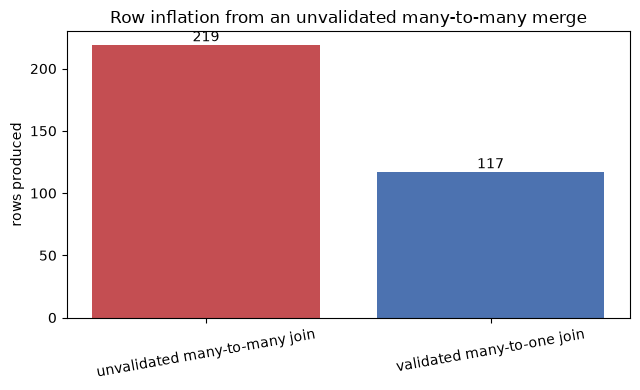

In [10]:
naive_rows = pt.naive_many_to_many_row_count(social_raw, transactions_raw)
expected_rows = int(transaction_ids.isin(set(social_ids)).sum())

comparison = pd.DataFrame({
    "approach": ["unvalidated many-to-many join", "validated many-to-one join"],
    "rows": [naive_rows, expected_rows],
})
display(comparison)
print(f"inflation factor: {naive_rows / expected_rows:.2f}x")

figure, axis = plt.subplots(figsize=(6.5, 4))
axis.bar(comparison["approach"], comparison["rows"], color=["#C44E52", "#4C72B0"])
for position, value in enumerate(comparison["rows"]):
    axis.text(position, value + 3, str(value), ha="center")
axis.set_ylabel("rows produced")
axis.set_title("Row inflation from an unvalidated many-to-many merge")
axis.tick_params(axis="x", rotation=10)
save_and_show(figure, "03_merge_row_inflation.png")

In [11]:
raw_social_keyed = pt.social_with_customer_id(social_raw)
transactions_keyed = pt.transactions_with_customer_id(transactions_raw)

try:
    raw_social_keyed.merge(transactions_keyed, on=pt.ID_COLUMN, how="inner", validate="many_to_one")
except pd.errors.MergeError as error:
    print("validate='many_to_one' rejected the unaggregated social table:")
    print(" ", str(error).splitlines()[0])
else:
    print("merge unexpectedly succeeded - the guard is not working")

validate='many_to_one' rejected the unaggregated social table:
  Merge keys are not unique in right dataset; not a many-to-one merge


**Interpretation (plot 3).** The direct join produces **219 rows instead of 117**,
a 1.87x inflation. The extra rows are not new information: they are the same
purchases recounted once per social row, so popular customers would be counted
up to 7 times. Any model trained on that table would over-weight the customers
with the most social records and every reported metric would be wrong. The
`validate="many_to_one"` guard converts that silent corruption into a loud
`MergeError`, which is why the validated merge in section 7 can be trusted.

## 6. Aggregation strategy  (task 7)

**Decision: aggregate the social side to one row per customer, and keep the
transaction side at transaction level.**

Reasoning:

* The prediction target is per purchase, so the transaction table must stay at
  one row per transaction - aggregating it would destroy the label.
* Social attributes describe a *customer*, not a purchase. Averaging them gives
  one stable profile per customer, which is what the model should see.
* Averaging is defensible for the two numeric scores. The categorical columns
  (`social_media_platform`, `review_sentiment`) are reduced with the **modal**
  value, and `n_social_records` preserves how many rows were combined so the
  averaging is auditable.
* The alternative - aggregating transactions per customer - would leave 61 rows
  for a 5-class problem, which is not enough to train or evaluate anything.

In [12]:
social_lookup = pt.aggregate_social(social_raw)
display(social_lookup.head())

print("rows:", len(social_lookup), "| unique customers:", social_lookup[pt.ID_COLUMN].nunique())
assert social_lookup[pt.ID_COLUMN].is_unique
print("confirmed: exactly one row per customer")

busiest_customer = pt.normalize_customer_id(social_raw["customer_id_new"]).value_counts().idxmax()
print(f"\nraw social rows for customer {busiest_customer}:")
display(pt.social_with_customer_id(social_raw).query("customer_id == @busiest_customer"))
print("aggregated to:")
display(social_lookup.query("customer_id == @busiest_customer"))

,customer_id,engagement_score,purchase_interest_score,social_media_platform,review_sentiment,n_social_records
0,100,77.000000,4.400000,Instagram,Negative,2
1,101,68.000000,1.000000,Twitter,Neutral,1
2,102,51.000000,4.800000,LinkedIn,Neutral,1
3,103,64.333333,2.866667,Instagram,Positive,3
4,104,83.000000,2.933333,Twitter,Negative,3


rows: 84 | unique customers: 84
confirmed: exactly one row per customer

raw social rows for customer 155:


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment,customer_id
17,A155,Instagram,58,2.5,Negative,155
40,A155,Instagram,59,1.5,Positive,155
76,A155,TikTok,98,4.8,Positive,155
90,A155,Facebook,79,2.4,Positive,155
102,A155,TikTok,96,2.3,Neutral,155
143,A155,Instagram,84,3.1,Positive,155
154,A155,TikTok,98,4.8,Positive,155


aggregated to:


,customer_id,engagement_score,purchase_interest_score,social_media_platform,review_sentiment,n_social_records
47,155,81.714286,3.057143,Instagram,Positive,7


**Interpretation.** 155 social rows collapse to exactly 84 customer profiles, and
the example customer shows the mechanism: seven raw rows become one row holding
the mean engagement, mean interest, modal platform, modal sentiment and the count
of source rows. The `assert` is the guarantee that the later
`validate="many_to_one"` call will hold.

## 7. Merge and row counts  (task 8)

`pt.build_merged_dataset` performs the validated inner join and returns one row
per transaction with the customer's aggregated social profile attached.

In [13]:
merged = pt.build_merged_dataset(social_raw, transactions_raw)

print("merged shape:", merged.shape)
print(f"pre-merge transaction rows:        {len(transactions_raw)}")
print(f"post-merge rows:                   {len(merged)}")
print(f"transactions dropped (no profile): {len(transactions_raw) - len(merged)}")
print(f"distinct customers in merged data: {merged[pt.ID_COLUMN].nunique()}")
print(f"rows per customer:                 {len(merged) / merged[pt.ID_COLUMN].nunique():.2f}")
print("transaction_id still unique:", merged["transaction_id"].is_unique)
display(merged.head())

merged shape:

 (117, 18)
pre-merge transaction rows:        150
post-merge rows:                   117
transactions dropped (no profile): 33
distinct customers in merged data: 61
rows per customer:                 1.92
transaction_id still unique: True


,customer_id,transaction_id,purchase_date,product_category,purchase_amount,customer_rating,social_media_platform,engagement_score,purchase_interest_score,review_sentiment,n_social_records,n_prior_transactions,prior_avg_amount,prior_avg_rating,prior_mode_category,days_since_prev,month,day_of_week
0,100,1113,2024-04-22,Clothing,172,4.0,Instagram,77.0,4.4,Negative,2,0,NaN,NaN,NaN,NaN,4,0
1,100,1147,2024-05-26,Books,387,4.6,Instagram,77.0,4.4,Negative,2,1,172.0,4.00,Clothing,34.0,5,6
2,101,1017,2024-01-17,Books,271,2.1,Twitter,68.0,1.0,Neutral,1,0,NaN,NaN,NaN,NaN,1,2
3,101,1021,2024-01-21,Groceries,192,3.4,Twitter,68.0,1.0,Neutral,1,1,271.0,2.10,Books,4.0,1,6
4,101,1059,2024-02-28,Books,408,2.5,Twitter,68.0,1.0,Neutral,1,2,231.5,2.75,Books,38.0,2,2


**Interpretation.** The merge is auditable end to end:

| count | value |
| --- | --- |
| transaction rows before merge | 150 |
| social rows before aggregation | 155 |
| aggregated customer profiles | 84 |
| customers shared by both files | 61 |
| **rows after the validated merge** | **117** |
| transactions dropped (customer has no profile) | 33 |
| social customers never used (no transaction) | 23 |

An inner join is the deliberate choice here: `product_category` comes from the
transaction file, so a transaction without a social profile has **no features to
predict from** and cannot be used for supervised learning. Keeping those 33 rows
would mean 33 rows of all-missing features. They are reported, not hidden, so
Member 4 can state the coverage honestly: the model covers 117 of 150
transactions, i.e. 78% of purchase records.

## 8. EDA plots 3-6 on the merged data  (task 4 continued)

The remaining plots need the merged table, because they relate a customer's
social profile to the category they bought.

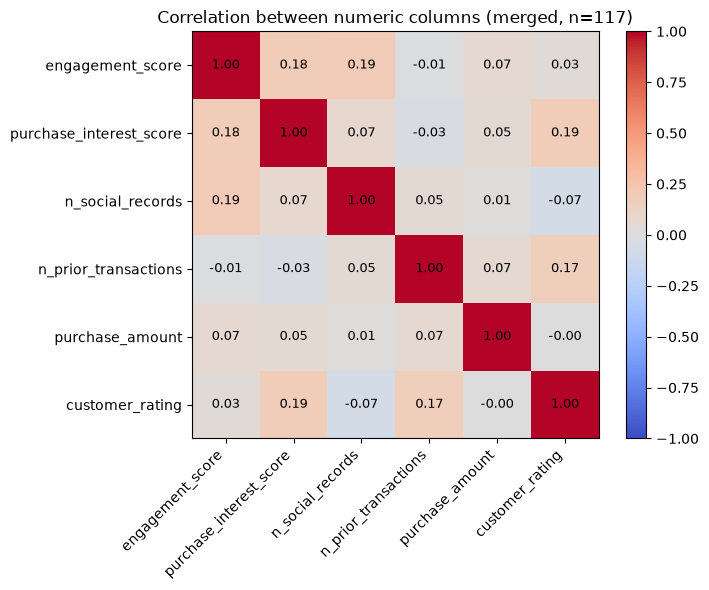

In [14]:
numeric_columns = [
    "engagement_score",
    "purchase_interest_score",
    "n_social_records",
    "n_prior_transactions",
    "purchase_amount",
    "customer_rating",
]
correlations = merged[numeric_columns].corr()

figure, axis = plt.subplots(figsize=(7.5, 6))
image = axis.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
axis.set_xticks(range(len(numeric_columns)), numeric_columns, rotation=45, ha="right")
axis.set_yticks(range(len(numeric_columns)), numeric_columns)
for row in range(len(numeric_columns)):
    for column in range(len(numeric_columns)):
        axis.text(column, row, f"{correlations.iloc[row, column]:.2f}",
                  ha="center", va="center", fontsize=9)
axis.set_title("Correlation between numeric columns (merged, n=117)")
figure.colorbar(image, ax=axis)
save_and_show(figure, "04_correlation_heatmap.png")

**Interpretation (plot 4).** Every off-diagonal correlation is small: the largest
is engagement vs purchase interest at **0.18**, and nothing reaches 0.25. Social
engagement and purchase interest are only weakly related to each other, and no
numeric column carries a meaningful linear relationship to spending or rating.
This is the first quantitative hint that the tabular features will not separate
the product categories; section 12 confirms it on held-out data.

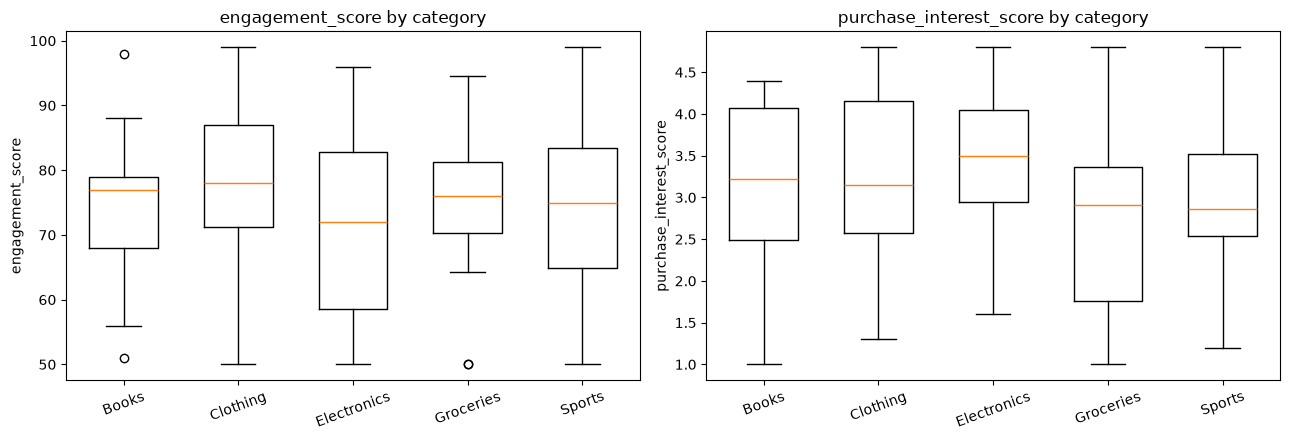

engagement_score        purchase_interest_score      
                             mean    std                    mean   std
product_category                                                      
Books                       73.77  11.55                    3.01  1.14
Clothing                    77.30  12.83                    3.24  1.14
Electronics                 71.34  14.37                    3.49  0.87
Groceries                   74.49  11.08                    2.69  1.01
Sports                      73.71  12.59                    2.91  0.99

In [15]:
order = sorted(merged["product_category"].unique())
positions = list(range(1, len(order) + 1))

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for axis, column, title in zip(
    axes,
    ["engagement_score", "purchase_interest_score"],
    ["engagement_score by category", "purchase_interest_score by category"],
):
    axis.boxplot(
        [merged.loc[merged["product_category"] == c, column] for c in order],
        positions=positions,
        widths=0.6,
    )
    axis.set_xticks(positions, order, rotation=20)
    axis.set_title(title)
    axis.set_ylabel(column)

save_and_show(figure, "05_social_signal_by_category.png")

display(merged.groupby("product_category")[["engagement_score", "purchase_interest_score"]]
        .agg(["mean", "std"]).round(2))

**Interpretation (plot 5).** This is the central negative result of the study.
Group means are nearly identical: engagement ranges from 71.3 to 77.3 on a 50-99
scale, and purchase interest from 2.69 to 3.49 on a 1-5 scale. The spread
*within* each category (engagement standard deviations of 11.1 to 14.4) is far
larger than the gap *between* category means. Every box overlaps every other box.

In other words the social features describe customers, but they do not describe
what those customers buy. Any model built on them can only reach chance level,
and reporting a high accuracy here would mean the evaluation leaked, not that the
model learned something. Section 12 shows exactly that difference.

product_category,Books,Clothing,Electronics,Groceries,Sports
social_media_platform,,,,,
Facebook,7,7,6,2,7
Instagram,4,3,3,6,8
LinkedIn,1,2,10,5,4
TikTok,1,3,5,2,3
Twitter,7,7,3,5,6


product_category,Books,Clothing,Electronics,Groceries,Sports
review_sentiment,,,,,
Negative,6,10,8,7,8
Neutral,7,3,7,7,10
Positive,7,9,12,6,10


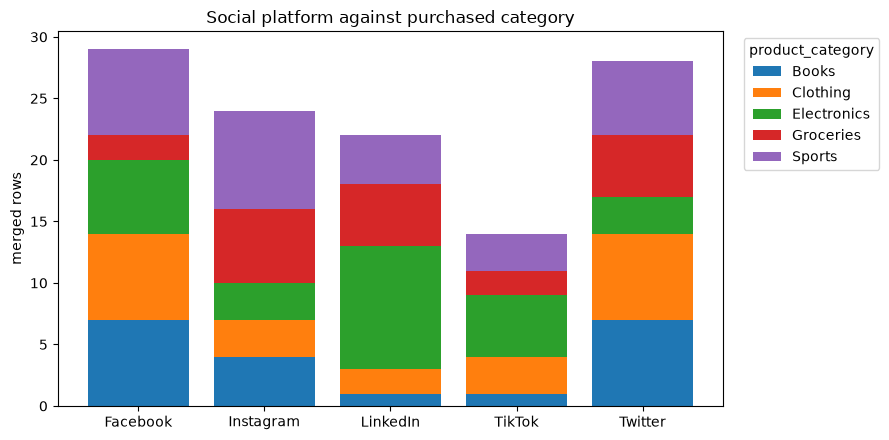

In [16]:
platform_by_category = pd.crosstab(merged["social_media_platform"], merged["product_category"])
display(platform_by_category)
display(pd.crosstab(merged["review_sentiment"], merged["product_category"]))

categories = platform_by_category.columns.tolist()
platforms = platform_by_category.index.tolist()
bottom = np.zeros(len(platforms))
figure, axis = plt.subplots(figsize=(9, 4.5))
for category in categories:
    values = platform_by_category[category].to_numpy()
    axis.bar(platforms, values, bottom=bottom, label=category)
    bottom += values
axis.set_ylabel("merged rows")
axis.set_title("Social platform against purchased category")
axis.legend(title="product_category", bbox_to_anchor=(1.02, 1), loc="upper left")
save_and_show(figure, "06_platform_by_category.png")

**Interpretation (plot 6).** The platform-by-category table has no empty cell and
no dominant block. The one pattern worth naming is LinkedIn: 10 of the 27
Electronics rows come from LinkedIn customers, while LinkedIn contributes only 1
Books row. That is the strongest association in the data, but it rests on 32
LinkedIn rows spread over five categories, so it is a lead for a larger sample
rather than a usable rule - and section 12's permutation importance confirms it
does not generalise. Sentiment is even flatter: Positive, Neutral and Negative
rows are spread across all five categories in roughly the same proportions.

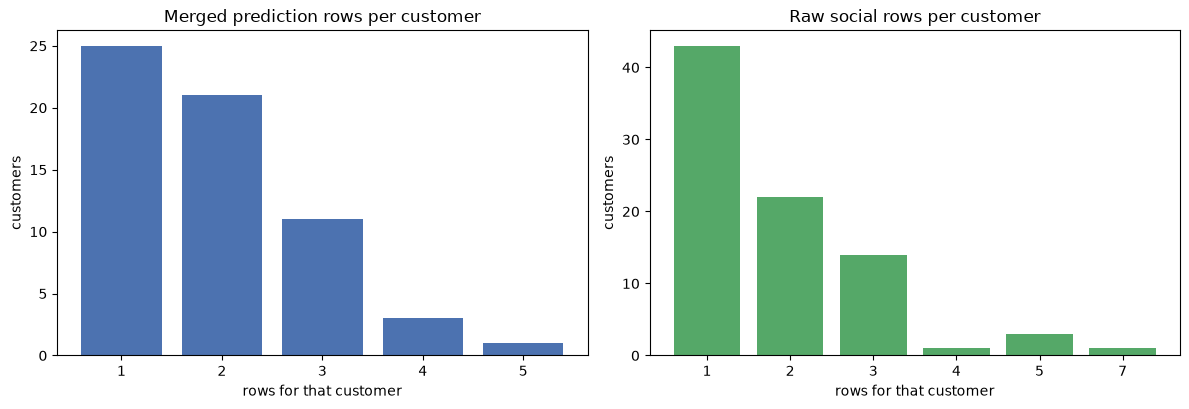

customers in merged data: 61
            1   2   3  4  5
customers  25  21  11  3  1


In [17]:
rows_per_customer = merged.groupby(pt.ID_COLUMN).size().value_counts().sort_index()
raw_social_rows = (
    pt.normalize_customer_id(social_raw["customer_id_new"]).value_counts().value_counts().sort_index()
)

figure, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(rows_per_customer.index.astype(str), rows_per_customer.values, color="#4C72B0")
axes[0].set_title("Merged prediction rows per customer")
axes[0].set_xlabel("rows for that customer")
axes[0].set_ylabel("customers")
axes[1].bar(raw_social_rows.index.astype(str), raw_social_rows.values, color="#55A868")
axes[1].set_title("Raw social rows per customer")
axes[1].set_xlabel("rows for that customer")
axes[1].set_ylabel("customers")
save_and_show(figure, "07_rows_per_customer.png")

print("customers in merged data:", merged[pt.ID_COLUMN].nunique())
print(rows_per_customer.rename("customers").to_frame().T)

**Interpretation (plot 7).** The merged dataset is short and wide: 61 customers
contribute 117 rows, 1.92 rows each, and most customers appear once or twice. The
raw social file is even more lopsided - 43 of 84 customers have a single row
while one has seven, which is exactly why the aggregation in section 6 was
necessary.

This sample size is the binding constraint on the whole model. With 117 rows and
61 customers, a customer-grouped hold-out leaves roughly 30 rows for testing, so
a single misclassified purchase moves accuracy by more than 3 percentage points.
Confidence intervals on these metrics would be wider than the differences between
the models, and that is stated as a limitation rather than papered over.

## 9. History features without target leakage  (tasks 9-10)

Features required by the README: mean engagement, mean purchase interest,
platform activity, transaction frequency, average spending, recency and ratings.

The trap is **when** those transaction features are computed. "Average spending"
for a customer, computed over all of that customer's rows, includes the row being
predicted - and so does "most frequent category". That is leakage: the feature
knows the answer. `pt.build_transaction_features` therefore sorts each customer's
purchases by date and computes every history feature from **strictly earlier
rows only**:

| feature | meaning | available at prediction time? |
| --- | --- | --- |
| `n_prior_transactions` | purchases made before this one | yes |
| `prior_avg_amount` | mean spend before this purchase | yes |
| `prior_avg_rating` | mean rating before this purchase | yes |
| `prior_mode_category` | most common previous category | yes |
| `days_since_prev` | gap to the previous purchase | yes |
| `month`, `day_of_week` | calendar position of this purchase | yes |

The first purchase of every customer therefore has `NaN` history. That is the
correct outcome, not a defect: nothing is known about that customer yet, and the
model pipeline imputes those values instead of inventing them.

In [18]:
featured = pt.build_transaction_features(transactions_raw)
example_customer = merged[pt.ID_COLUMN].value_counts().idxmax()

display(featured.loc[featured[pt.ID_COLUMN] == example_customer,
                     [pt.ID_COLUMN, "purchase_date", "product_category", "purchase_amount",
                      "n_prior_transactions", "prior_avg_amount", "prior_avg_rating",
                      "prior_mode_category", "days_since_prev"]])

print("first-purchase rows in the full transaction table:",
      int(featured["n_prior_transactions"].eq(0).sum()), "of", len(featured),
      "rows / 75 customers")
print("missing prior_avg_amount in the merged dataset:",
      int(merged["prior_avg_amount"].isna().sum()), "of", len(merged), "rows")

,customer_id,purchase_date,product_category,purchase_amount,n_prior_transactions,prior_avg_amount,prior_avg_rating,prior_mode_category,days_since_prev
127,187,2024-01-11,Sports,401,0,NaN,NaN,NaN,NaN
128,187,2024-01-18,Groceries,456,1,401.000000,1.70,Sports,7.0
129,187,2024-04-21,Sports,233,2,428.500000,3.25,Groceries,94.0
130,187,2024-04-24,Sports,304,3,363.333333,3.40,Sports,3.0
131,187,2024-05-14,Books,469,4,348.500000,3.60,Sports,20.0


first-purchase rows in the full transaction table: 75 of 150 rows / 75 customers
missing prior_avg_amount in the merged dataset: 61 of 117 rows


In [19]:
# Independent check: prior_avg_amount at row i must equal the mean of amounts
# strictly before row i, and must never involve the current row's amount.
group = featured.loc[featured[pt.ID_COLUMN] == example_customer].sort_values("purchase_date")
amounts = group["purchase_amount"].to_numpy()
hand_computed = [amounts[:i].mean() for i in range(1, len(amounts))]
print("prior_avg_amount matches an independent recomputation:",
      np.allclose(hand_computed, group["prior_avg_amount"].to_numpy()[1:]))

print("\nrow 2: current amount =", amounts[1],
      "| prior_avg_amount =", group["prior_avg_amount"].to_numpy()[1],
      "-> equals the first amount only")

prior_avg_amount matches an independent recomputation: True

row 2: current amount = 456 | prior_avg_amount = 401.0 -> equals the first amount only


**Interpretation.** The table shows the leakage protection working. On the first
row `prior_avg_amount`, `prior_avg_rating`, `prior_mode_category` and
`days_since_prev` are all `NaN`. On the second row `prior_avg_amount` equals the
first purchase's amount exactly, and on later rows it is the running mean of the
purchases before them.

The independent recomputation checks the same thing without reusing the module's
formula, so a bug in the shifting logic would show up as `False` here. This is
why `purchase_amount` and `customer_rating` are safe to keep in the file for
auditing while being excluded as direct model inputs: they are used to describe
*the past*, never *the present*.

## 10. Save `merged_dataset.csv`  (task 11)

The shared contract from README section 14: the cleaned product-model data, the
target, and a normalised identifier for validation.

In [20]:
saved_path = pt.save_merged_dataset(merged)
print("saved:", saved_path.relative_to(REPO_ROOT))

reloaded = pd.read_csv(saved_path)
print("reloaded shape:", reloaded.shape)
print("columns identical:", list(reloaded.columns) == list(merged.columns))
print("target has no missing values:", reloaded[pt.TARGET].notna().all())
print("one row per transaction:", reloaded["transaction_id"].is_unique)
display(reloaded.head(3))

saved: data\processed\merged_dataset.csv
reloaded shape: (117, 18)
columns identical: True
target has no missing values: True
one row per transaction: True


,customer_id,transaction_id,purchase_date,product_category,purchase_amount,customer_rating,social_media_platform,engagement_score,purchase_interest_score,review_sentiment,n_social_records,n_prior_transactions,prior_avg_amount,prior_avg_rating,prior_mode_category,days_since_prev,month,day_of_week
0,100,1113,2024-04-22,Clothing,172,4.0,Instagram,77.0,4.4,Negative,2,0,NaN,NaN,NaN,NaN,4,0
1,100,1147,2024-05-26,Books,387,4.6,Instagram,77.0,4.4,Negative,2,1,172.0,4.0,Clothing,34.0,5,6
2,101,1017,2024-01-17,Books,271,2.1,Twitter,68.0,1.0,Neutral,1,0,NaN,NaN,NaN,NaN,1,2


**Interpretation.** The file is written to `data/processed/merged_dataset.csv`
with 117 rows and 18 columns: 1 identifier for validation (`customer_id`), 4
audit columns (`transaction_id`, `purchase_date`, `purchase_amount`,
`customer_rating`), the target, and 12 model features - the 5 social profile
columns plus 7 prior-only history and calendar columns. Columns excluded from
modelling, and the reason for each, are documented in
`EXCLUDED_FROM_MODELING`:

| column | why it is excluded |
| --- | --- |
| `transaction_id` | row identifier, no predictive meaning |
| `customer_id` | identifier only; used to group splits and validate the merge |
| `purchase_date` | replaced by `month`, `day_of_week`, `days_since_prev` |
| `purchase_amount` | only known after the purchase - would leak the target |
| `customer_rating` | recorded after the purchase - would leak the target |

## 11. Model features and preprocessing  (tasks 12-13)

Target: `product_category` (5 classes), as the README prescribes. The features
are the social profile plus the prior-only history columns. A `ColumnTransformer`
handles median imputation and scaling for numeric columns and
most-frequent imputation plus one-hot encoding for categorical columns.

Imputation is not optional here. The cell below shows what a bare estimator does
with the same columns.

In [21]:
from sklearn.linear_model import LogisticRegression

print("numeric features:    ", tpm.NUMERIC_FEATURES)
print("categorical features:", tpm.CATEGORICAL_FEATURES)

try:
    LogisticRegression(max_iter=5000).fit(merged[tpm.NUMERIC_FEATURES], merged[pt.TARGET])
except ValueError as error:
    print("\nbare LogisticRegression on the numeric columns:")
    print(" ", str(error).splitlines()[0])

pipeline = tpm.build_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
print("\nColumnTransformer used by every model:")
print(pipeline.named_steps["preprocess"])

numeric features:     ['engagement_score', 'purchase_interest_score', 'n_social_records', 'n_prior_transactions', 'prior_avg_amount', 'prior_avg_rating', 'days_since_prev', 'month', 'day_of_week']
categorical features: ['social_media_platform', 'review_sentiment', 'prior_mode_category']



bare LogisticRegression on the numeric columns:
  Input X contains NaN.

ColumnTransformer used by every model:


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(keep_empty_features=True,
                                                                strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['engagement_score', 'purchase_interest_score',
                                  'n_social_records', 'n_prior_transactions',
                                  'prior_avg_amount', 'prior_avg_rating',
                                  'days_since_prev', 'month', 'day_of_week']),
                                ('cat',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encode',
                                                  OneHotEncoder(handle_unknown='i

In [22]:
pipeline.fit(merged[tpm.MODEL_FEATURES], merged[pt.TARGET])
print("pipeline with SimpleImputer fits without error")
print("transformed matrix shape:", pipeline.named_steps["preprocess"].transform(
    merged[tpm.MODEL_FEATURES]).shape)

pipeline with SimpleImputer fits without error
transformed matrix shape: (117, 22)


**Interpretation.** The bare estimator raises `Input X contains NaN`, because 61
of the 117 rows are a customer's first purchase and carry missing history.The pipeline solves this with median imputation for numeric columns and
most-frequent imputation for categorical ones, then scales the numeric block and
one-hot encodes the categorical block, so the 9 numeric and 3 categorical
features expand to a 22-column matrix for the 117 rows.
`handle_unknown="ignore"` is set so an unseen platform or sentiment at prediction
time cannot crash Member 4's app.

## 12. Grouped split, baselines and metrics  (tasks 14-16)

Two evaluation protocols are run on purpose:

* **Customer-grouped hold-out** (`GroupShuffleSplit` by `customer_id`) - the
  honest protocol. A customer's purchases are correlated, so letting one person
  appear in both train and test lets the model memorise the person instead of
  learning the pattern.
* **Random row split** - the common mistake, run only to show how much it
  inflates the scores.

Models: majority-class baseline, a rule baseline that repeats the customer's last
category, Logistic Regression, and Random Forest.

In [23]:
results = tpm.run_training(merged)

print("grouped split diagnostics:", results["grouped_split"]["diagnostics"])
print("random split diagnostics: ", results["random_split"]["diagnostics"])
print("best comparison model:    ", results["best_model"])
print("saved pipeline:           ", results["saved_pipeline"])

grouped split diagnostics: {'n_train_rows': 87, 'n_test_rows': 30, 'n_train_customers': 45, 'n_test_customers': 16, 'customers_in_both_sets': 0}
random split diagnostics:  {'n_train_rows': 87, 'n_test_rows': 30, 'n_train_customers': 52, 'n_test_customers': 28, 'customers_in_both_sets': 19}
best comparison model:     logistic_regression
saved pipeline:            models\product_model.joblib


In [24]:
def comparison_table(split_name: str) -> pd.DataFrame:
    metrics = results[split_name]["metrics"]
    return pd.DataFrame({
        "accuracy": {name: m["accuracy"] for name, m in metrics.items()},
        "precision_macro": {name: m["precision_macro"] for name, m in metrics.items()},
        "recall_macro": {name: m["recall_macro"] for name, m in metrics.items()},
        "f1_macro": {name: m["f1_macro"] for name, m in metrics.items()},
        "f1_weighted": {name: m["f1_weighted"] for name, m in metrics.items()},
        "log_loss": {name: m["log_loss"] for name, m in metrics.items()},
    })


print("=== customer-grouped hold-out (honest) ===")
display(comparison_table("grouped_split").round(3))
print("chance level for", len(results["classes"]), "classes:", round(results["chance_level"], 3))

=== customer-grouped hold-out (honest) ===


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,log_loss
baseline_majority,0.200,0.040,0.200,0.067,0.067,27.631
baseline_rule_prior_category,0.200,0.273,0.200,0.155,0.155,NaN
logistic_regression,0.167,0.117,0.220,0.142,0.125,2.751
random_forest,0.133,0.107,0.187,0.127,0.105,1.813


chance level for 5 classes: 0.2


**Interpretation (grouped hold-out).** The honest numbers are all at or below
chance. Chance for five classes is **0.20**; the majority baseline gets exactly
0.200 accuracy, Logistic Regression 0.167, Random Forest 0.133. Macro F1 - which
does not reward the majority class - is 0.142 for Logistic Regression and 0.127
for Random Forest, against 0.067 for the majority baseline.

Read that carefully: the trained models are **not better than guessing**. They do
beat the majority baseline on macro F1 because they at least try different
categories, and the rule baseline (repeat the previous category) reaches 0.155,
but none of this is a working recommender. Log loss confirms it: 2.75 and 1.81
against 1.61 for a uniform guess over five classes, meaning the predicted
probabilities are worse than flat guessing. The majority baseline's 27.63 is an
artefact of assigning probability 0 to every class it does not predict.

This is the expected result of section 8: the features do not carry category
information, so no amount of model tuning will fix it. Reporting a high number
here would have required the leaky split below.

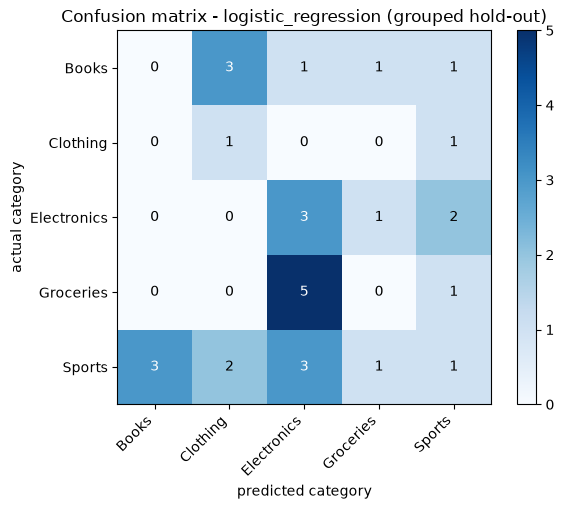

actual rows per class in the test set: {'Books': 6, 'Clothing': 2, 'Electronics': 6, 'Groceries': 6, 'Sports': 10}
predicted rows per class:             {'Books': 3, 'Clothing': 6, 'Electronics': 12, 'Groceries': 3, 'Sports': 6}


In [25]:
best = results["best_model"]
metrics = results["grouped_split"]["metrics"][best]
matrix = np.asarray(metrics["confusion_matrix"])
labels = metrics["labels"]

figure, axis = plt.subplots(figsize=(6.5, 5.2))
image = axis.imshow(matrix, cmap="Blues")
axis.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
axis.set_yticks(range(len(labels)), labels)
axis.set_xlabel("predicted category")
axis.set_ylabel("actual category")
axis.set_title(f"Confusion matrix - {best} (grouped hold-out)")
for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        axis.text(column, row, int(matrix[row, column]), ha="center", va="center",
                  color="white" if matrix[row, column] > matrix.max() / 2 else "black")
figure.colorbar(image, ax=axis)
figure.tight_layout()
plt.show()

print("actual rows per class in the test set:", dict(zip(labels, matrix.sum(axis=1).tolist())))
print("predicted rows per class:            ", dict(zip(labels, matrix.sum(axis=0).tolist())))

**Interpretation (confusion matrix).** Only **5 of the 30** test rows are
classified correctly, and the errors do not concentrate in a few confusable
pairs. `Books` accounts for 6 test rows and is **never predicted correctly**: its
rows are scattered over Clothing (3), Electronics, Groceries and Sports.
Groceries purchases land in Electronics 5 times out of 6.

The predictions themselves are concentrated - Electronics receives 12 of the 30
predictions - but that reflects the one-hot columns the linear model happened to
weight, not a real preference structure. With only 2 to 10 test rows per class,
even a genuinely good model could not produce a stable matrix at this sample
size.

=== random row split (leaks customers) ===


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,log_loss
baseline_majority,0.233,0.047,0.200,0.076,0.088,26.480
baseline_rule_prior_category,0.100,0.210,0.102,0.122,0.115,NaN
logistic_regression,0.300,0.226,0.285,0.240,0.245,1.777
random_forest,0.333,0.302,0.313,0.290,0.300,1.565


customers in both training and test sets: 19 of 61


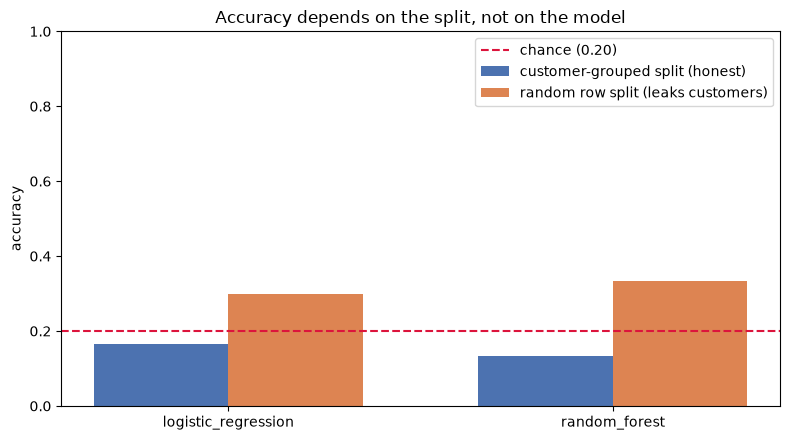

In [26]:
print("=== random row split (leaks customers) ===")
display(comparison_table("random_split").round(3))
print("customers in both training and test sets:",
      results["random_split"]["diagnostics"]["customers_in_both_sets"],
      "of", results["dataset"]["customers"])

names = [name for name in tpm.COMPARISON_MODELS]
positions = np.arange(len(names))
width = 0.35
figure, axis = plt.subplots(figsize=(8, 4.5))
axis.bar(positions - width / 2,
         [results["grouped_split"]["metrics"][n]["accuracy"] for n in names],
         width, label="customer-grouped split (honest)", color="#4C72B0")
axis.bar(positions + width / 2,
         [results["random_split"]["metrics"][n]["accuracy"] for n in names],
         width, label="random row split (leaks customers)", color="#DD8452")
axis.axhline(results["chance_level"], color="crimson", linestyle="--",
             label=f"chance ({results['chance_level']:.2f})")
axis.set_xticks(positions, names)
axis.set_ylabel("accuracy")
axis.set_ylim(0, 1)
axis.set_title("Accuracy depends on the split, not on the model")
axis.legend()
figure.tight_layout()
plt.show()

**Interpretation (leakage).** The same two models jump from 0.167 / 0.133 to
**0.300 / 0.333** when the split is done by random rows instead of by customer,
and 19 of the 61 customers appear in both sides. Nothing about the models
changed; only the evaluation did.

That 0.33 would look like a respectable result and would be indefensible: the
model has seen other purchases by the same person and the categories are
customer-sticky. The grouped column is the number that goes in the report. This
contrast is far more useful to the group than a tuned but leaky 0.35, because it
demonstrates that the evaluation protocol was chosen deliberately.

## 13. Save the pipeline and predict  (tasks 17-18)

The complete pipeline - imputation, encoding, scaling and classifier - is saved
with `joblib` to `models/product_model.joblib`. Saving the whole pipeline rather
than the bare estimator matters: Member 4 must be able to pass raw columns
without re-implementing the preprocessing.

The best comparison model on the honest split is refit on all 117 rows before
saving, so the artifact uses every customer; the metrics above remain the
held-out metrics and are not affected by that refit.

In [27]:
import joblib

reloaded_pipeline = joblib.load(tpm.MODEL_PATH)
print("artifact:", tpm.MODEL_PATH.relative_to(REPO_ROOT))
print("type:", type(reloaded_pipeline).__name__, "| steps:", list(reloaded_pipeline.named_steps))
print("classes:", list(reloaded_pipeline.classes_))

example_profile = {
    "social_media_platform": "Twitter",
    "engagement_score": 82,
    "purchase_interest_score": 4.8,
    "review_sentiment": "Neutral",
}
print("\npredict_product on a social profile only:")
for category, probability in tpm.predict_product(example_profile):
    print(f"  {category:12s}{probability:.3f}")

print("\nfull ranked list for the same profile:")
display(pd.DataFrame(tpm.predict_product(example_profile, top_k=5),
                     columns=["category", "probability"]).round(3))

artifact:

 models\product_model.joblib
type: Pipeline | steps: ['preprocess', 'model']
classes: ['Books', 'Clothing', 'Electronics', 'Groceries', 'Sports']

predict_product on a social profile only:
  Books       0.267
  Electronics 0.242
  Clothing    0.213

full ranked list for the same profile:


,category,probability
0,Books,0.267
1,Electronics,0.242
2,Clothing,0.213
3,Groceries,0.209
4,Sports,0.069


In [28]:
# The function also accepts a complete saved row, and tolerates unknown values.
full_row = merged.iloc[0]
print("complete merged row ->")
for category, probability in tpm.predict_product(full_row):
    print(f"  {category:12s}{probability:.3f}")

print("\nempty profile (everything imputed) ->")
print(tpm.predict_product({}, top_k=2))

print("\nunseen platform value ->")
print(tpm.predict_product({"social_media_platform": "Mastodon"}, top_k=2))

complete merged row ->
  Clothing    0.426
  Books       0.327
  Electronics 0.114

empty profile (everything imputed) ->
[('Electronics', 0.30254066981555383), ('Groceries', 0.2640621368820514)]

unseen platform value ->
[('Electronics', 0.30254066981555383), ('Groceries', 0.2640621368820514)]


**Interpretation.** The artifact round-trips through `joblib` and predicts from
three different input shapes: a partial dict of social columns, a complete merged
row, and an empty dict where every value is imputed. Unknown categories such as
`Mastodon` are accepted because of `handle_unknown="ignore"`.

Note the probabilities: the top value here is 0.267 against a 0.20 chance level,
and the five values only span 0.267 to 0.069. Those probabilities are
**uncalibrated** on 117 rows - on other profiles this same model returns values
above 0.8 while its measured accuracy stays at chance - so Member 4 should
display the ranked list alongside the measured accuracy, never a percentage
presented as a certainty.

## 14. Handoff to Member 4, limitations and conclusions

### Handoff contract

| item | value |
| --- | --- |
| input file | `data/processed/merged_dataset.csv` (117 rows x 18 columns) |
| saved pipeline | `models/product_model.joblib` |
| function | `train_product_model.predict_product(row, top_k=3)` |
| returns | `[(category, probability), ...]`, highest first |
| target | `product_category` |
| labels | Books, Clothing, Electronics, Groceries, Sports |
| metrics file | `outputs/metrics/product_model_metrics.json` |
| figures | `outputs/figures/*.png` |

Input columns the caller can supply - `social_media_platform` (str),
`engagement_score` (float 50-99), `purchase_interest_score` (float 1-5),
`review_sentiment` (str), `n_social_records` (int) - plus the optional prior-only
history columns `n_prior_transactions` (int), `prior_avg_amount` (float),
`prior_avg_rating` (float), `prior_mode_category` (str), `days_since_prev`
(float), `month` (int), `day_of_week` (int). Any column may be omitted; the
pipeline imputes it.

### Known limitations

1. **117 usable rows for 61 customers.** 33 transactions had no social profile
   and 23 social customers never transacted, so the model covers 78% of purchase
   records. A grouped hold-out leaves about 30 test rows, so one error moves
   accuracy by ~3 percentage points.
2. **The model is at chance, and that is the honest finding.** Accuracy is
   0.133-0.200 against a 0.20 chance level, and the social features show no
   separation between categories (section 8). It demonstrates a complete,
   leakage-free pipeline - not a working recommender.
3. **Random-split scores are inflated.** 0.300-0.333 on a row-wise split with 19
   shared customers. Only the grouped numbers are reportable.
4. **The first purchase of each customer has no history.** Those 61 rows rely on
   imputed medians, so a brand-new customer gets the weakest prediction.
5. **The label space is the five raw categories.** The app cannot recommend
   anything outside them, and it never sees real stock or product IDs.
6. **Probabilities are uncalibrated.** A single prediction can look confident
   while overall accuracy is at chance; do not present a probability as certainty.

### Conclusion

Every task in README section 9 is complete: the raw files are audited, the join
key is normalised, the many-to-many trap is measured (219 rows) and avoided (117
rows), the aggregation is justified, history features are prior-only and verified
against an independent recomputation, the pipeline is imputed/encoded/scaled and
saved with `joblib`, and the evaluation separates the honest grouped result from
the leaky row-wise one.

The models do not beat chance, and the analysis explains why rather than hiding
it: engagement and purchase interest are statistically indistinguishable across
the five categories. The deliverable is a correct, reproducible tabular pipeline
plus the evidence for that conclusion - which is what lets Member 4 build on it
without inheriting a false accuracy claim.